# Component 0: what is in the diet logs (LONGIT-weeklong)

A descriptive look at the coded diet logs, used by both analysis components: which ingredients people logged, how often
they logged live-microbe, fermented, fibrous and dairy foods, and whether the logs agree with the pre-study questionnaire.
No sequencing data are used and nothing is tested. Reusable code is in `scripts/diet_log.py`; the workflow is in
`diet_log_analyses/CLAUDE.md`.

Figures are shown here and saved to `figures/component0_diet_logs/` as PNG (300 dpi) and PDF, each with the CSV it was drawn from.

## Parameters
Everything that can change a result is set here, once. The notebook may be run from any folder: the first lines
make `diet_log_analyses/scripts` importable, which also makes the shared modules in `2-analysis_python/` importable.

In [1]:
import sys
from pathlib import Path

# make diet_log_analyses/scripts importable when the notebook is run from another folder
here = Path.cwd()
scripts = next(p for p in [here, here / "diet_log_analyses" / "scripts", here / "scripts"] if (p / "_paths.py").exists())
sys.path.insert(0, str(scripts))

import json
import hashlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import _paths            # paths: FIG_DIR, DIET_CODING; also puts 2-analysis_python on sys.path
import config as C       # shared helpers (read_excel_like_readxl, ...)
import diet_log as DL    # diet-log tables and figures for these notebooks

FIG_FOLDER = "component0_diet_logs"   # all figures of this notebook go to figures/<FIG_FOLDER>/
TOP_N = 40                           # ingredients shown in the frequency figure
TOP_N_CATEGORY = 15                  # foods shown per food class
CLASS_LEVEL = "Yes"                  # lexicon value that puts a food in a class ("Variable" is not counted)

# config.py switches matplotlib to a non-display backend; show figures inline in the notebook again
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.family": "sans-serif"})
print("figures will be saved to:", _paths.FIG_DIR / FIG_FOLDER)

figures will be saved to: /Users/lisa/Documents/GitHub/gen2-longit/diet_log_analyses/figures/component0_diet_logs


## Input versions (workflow steps 0 and 2)
The input profiler (`scripts/profile_inputs.py`) records a checksum for every input in `figures/input_profiles/manifest.json`.
This cell recomputes the checksum of the diet workbook used here. **Expected:** it matches the manifest. A mismatch means the
workbook changed since it was last profiled: rerun the profiler and the tests before trusting anything below.

In [2]:
manifest = json.loads((_paths.FIG_DIR / "input_profiles" / "manifest.json").read_text())
sha_now = hashlib.sha256(_paths.DIET_CODING.read_bytes()).hexdigest()
entry = manifest["daily_diet_coding"]
print(f"diet workbook: {_paths.DIET_CODING.name}, modified {entry['modified']}")
print(f"checksum now:          {sha_now[:16]}…")
print(f"checksum in manifest:  {entry['sha256'][:16]}…")
print("MATCH: workbook unchanged since profiling" if sha_now == entry["sha256"] else "MISMATCH: rerun profile_inputs.py and the tests")

diet workbook: daily_diet_coding.xlsx, modified 2026-10-18T21:00:48
checksum now:          de90136d6a2fdc98…
checksum in manifest:  de90136d6a2fdc98…
MATCH: workbook unchanged since profiling


# 0. What is in the diet logs

A descriptive look at the coded diet logs only: which ingredients people logged most often, and how often they logged
live-microbe, fermented and fibrous foods. No microbiome data are used and nothing is tested.

**Unit of counting: the subject-day.** An ingredient counts once per subject per day, however many entries mention it,
because the log records what was eaten but not how much (CLAUDE.md, "Food entries").
A day is **stated** for an ingredient if at least one entry names it, and **assumed only** if it appears only as an
inferred component of a dish (marked `(assumed)` in the log, e.g. wheat in a sandwich).

### 0.1 Load the diet log
`DL.load()` reads the `daily_diet_coding` and `ingredient_lexicon` sheets and splits each entry's `Ingredients`
into one row per ingredient.

**Expected** (from the input report `figures/input_profiles/daily_diet_coding.md`): 1,461 food entries; 167 logged
subject-days; 19 subjects; subject 11 absent (no coded diet log).

In [3]:
entries, lexicon, mentions = DL.load()

# one row per logged subject-day (the denominator for every percentage below)
subject_days = entries[["subject", "date"]].drop_duplicates().sort_values(["subject", "date"]).reset_index(drop=True)
N_DAYS = len(subject_days)

print(f"food entries (rows of daily_diet_coding):          {len(entries):,}")
print(f"ingredient mentions (entry x ingredient):           {len(mentions):,}  "
      f"(stated {int(mentions.stated.sum()):,}, assumed {int((~mentions.stated).sum()):,})")
print(f"logged subject-days:                                {N_DAYS}")
print(f"subjects:                                           {entries.subject.nunique()}  {sorted(entries.subject.unique())}")
print(f"subject 11 present in the diet log:                 {'11' in set(entries.subject)}")

food entries (rows of daily_diet_coding):          1,461
ingredient mentions (entry x ingredient):           2,997  (stated 1,938, assumed 1,059)
logged subject-days:                                167
subjects:                                           19  ['01', '03', '04', '05', '06', '07', '08', '09', '10', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21']
subject 11 present in the diet log:                 False


### 0.2 Checks before plotting (workflow step 3)
Each check states its expected result first.
1. Every ingredient name, after stripping a trailing `(assumed)`, matches a lexicon `Ingredient` exactly. **Expected:** 0 unmatched.
2. Each subject-day has exactly one study-day label in `source_diet_text.Event_name` ("Day 01 ingestion " → 1, "Day 08" → 8).
   **Expected:** 167 labelled days, none missing or duplicated.
3. The frequency table built here reproduces the earlier `ingredient_frequency.csv` (old_scripts_figures; built from
   the same workbook). **Expected:** identical counts for all 226 ingredients.

In [4]:
# 1. every ingredient name matches the lexicon
unmatched = sorted(set(mentions.ingredient) - set(lexicon.Ingredient))
print(f"check 1, ingredient names not in the lexicon: {len(unmatched)} {unmatched[:5]}")

# 2. study day from source_diet_text.Event_name (number after "Day"), joined on subject + date
src = C.read_excel_like_readxl(_paths.DIET_CODING, sheet_name="source_diet_text")
src["subject"] = src["Subject_ID"].map(lambda s: f"{int(s):02d}")
src["date"] = pd.to_datetime("2025-" + src["Date (MM-DD)"].astype(str))
src["study_day"] = src["Event_name"].astype(str).str.extract(r"^Day (\d{2})")[0].astype(int)
n_before = len(subject_days)
subject_days = subject_days.merge(src[["subject", "date", "study_day"]], on=["subject", "date"], how="left")
print(f"check 2, subject-days before join {n_before}, after {len(subject_days)}, "
      f"missing study day {int(subject_days.study_day.isna().sum())}, "
      f"duplicated (subject, study day) {int(subject_days.duplicated(['subject', 'study_day']).sum())}")

# 3. frequency table vs the earlier output (reference only, read-only)
freq = DL.frequency(mentions, N_DAYS)
old = pd.read_csv(_paths.DIET_DIR / "old_scripts_figures" / "figures_Diet-logs" / "ingredient_frequency.csv")
cols = ["entries", "subject_days", "subjects", "days_stated", "days_assumed_only"]
cmp = freq.set_index("ingredient")[cols].join(old.set_index("ing")[cols], rsuffix="_old", how="outer")
mism = int(sum((cmp[c] != cmp[f"{c}_old"]).sum() for c in cols))
print(f"check 3, ingredients here {len(freq)}, in the earlier table {len(old)}, differing values {mism}")

check 1, ingredient names not in the lexicon: 0 []
check 2, subject-days before join 167, after 167, missing study day 0, duplicated (subject, study day) 0
check 3, ingredients here 226, in the earlier table 226, differing values 0


### 0.3 Most frequently logged ingredients
All ingredients, not only those the sequencing markers can detect. Labels give the lexicon species in brackets.

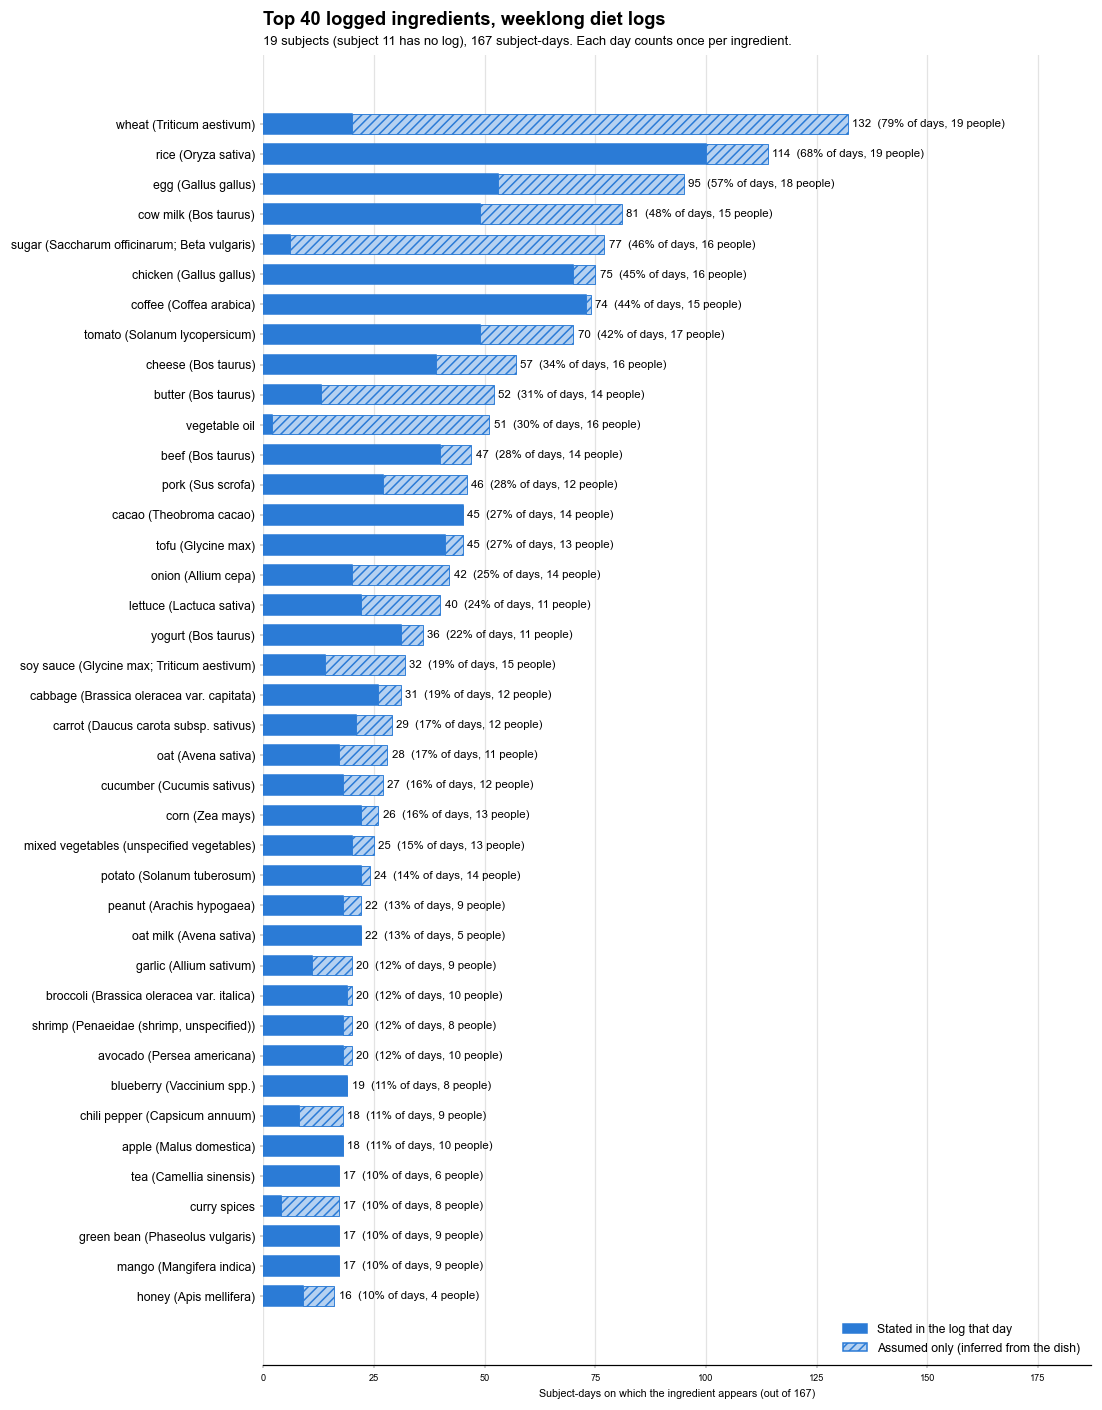

saved: 00_top40_ingredients.png, 00_top40_ingredients.pdf, 00_top40_ingredients.csv


In [5]:
# label = "ingredient (lexicon species)"; long multi-species recipes keep the ingredient name only
labels = {ing: f"{ing} ({sp})" if isinstance(sp, str) and len(sp) < 40 else ing
          for ing, sp in zip(lexicon["Ingredient"], lexicon["Species (scientific name)"])}
top = freq.head(TOP_N)
fig = DL.frequency_bars(top, labels, f"Top {TOP_N} logged ingredients, weeklong diet logs",
                        f"{entries.subject.nunique()} subjects (subject 11 has no log), {N_DAYS} subject-days. "
                        "Each day counts once per ingredient.", N_DAYS)
files = DL.save(fig, "00_top40_ingredients", top, FIG_FOLDER)
plt.show()
print("saved:", ", ".join(f.name for f in files))

**How to read it:** each bar is the number of subject-days (out of 167) on which the ingredient appears. The solid part
is days on which the person named it; the hatched part is days on which it was only inferred from a dish (e.g. wheat in
bread). The text gives the same count as a percentage of all logged days, and how many of the 19 people ate it at all.
Long hatched parts mean the count depends on the coding assumptions.

### 0.4 Food classes: live-microbe, fermented and fibrous
Classes come only from the lexicon (CLAUDE.md): a food is in a class when its lexicon value is `Yes`.
`Variable` foods (e.g. cheese for live microbes) are **not** counted here; they are listed so the definitions are visible.

In [6]:
sets = DL.category_sets(lexicon, CLASS_LEVEL)
variable = DL.category_sets(lexicon, "Variable")
for k, label in DL.CATEGORY_LABELS.items():
    foods = sorted(sets[k])
    shown = ", ".join(foods) if len(foods) <= 20 else ", ".join(foods[:20]) + f", … (+{len(foods) - 20} more)"
    print(f"{label} (lexicon '{DL.LEX_COLS[k].split(' (')[0]}' = Yes): {len(foods)} foods: {shown}")
    print(f"    'Variable', not counted: {len(variable[k])} foods: {', '.join(sorted(variable[k]))}")

Live-microbe foods (lexicon 'Likely live microbes?' = Yes): 3 foods: kimchi, natto, yogurt
    'Variable', not counted: 13 foods: beer, butter, caper, cheese, cream cheese, feta, goat cheese, miso, olive, protein powder, soybean paste, supplement, vegan cheese
Fermented foods (lexicon 'Fermented?' = Yes): 14 foods: balsamic vinegar, beer, cacao, cheese, cream cheese, feta, goat cheese, kimchi, miso, natto, soy sauce, soybean paste, wine, yogurt
    'Variable', not counted: 12 foods: anchovy, butter, caper, coffee, hoisin sauce, mustard, olive, protein powder, thousand island dressing, vegan caesar dressing, vegan cheese, whey
Fibrous foods (lexicon 'Fibrous?' = Yes): 135 foods: acai, almond, apple, artichoke, arugula, asian pear, asparagus, avocado, bamboo shoot, banana, basil, bean sprouts, beans (unspecified), beet, bell pepper, berries (mixed), black bean, black pepper, black soybean, black-eyed pea, … (+115 more)
    'Variable', not counted: 9 foods: gluten-free flour, grain cereal

### 0.5 How often each person ate each food class
For each subject: the percentage of their logged days with at least one food of the class (stated or assumed).
**Expected:** 167 subject-days in the table; every percentage between 0 and 100.

rows (subject-days): 167
Live-microbe foods: eaten on 55 of 167 subject-days; distinct foods per day: median 0, max 2
Fermented foods: eaten on 125 of 167 subject-days; distinct foods per day: median 1, max 5
Fibrous foods: eaten on 167 of 167 subject-days; distinct foods per day: median 7, max 21


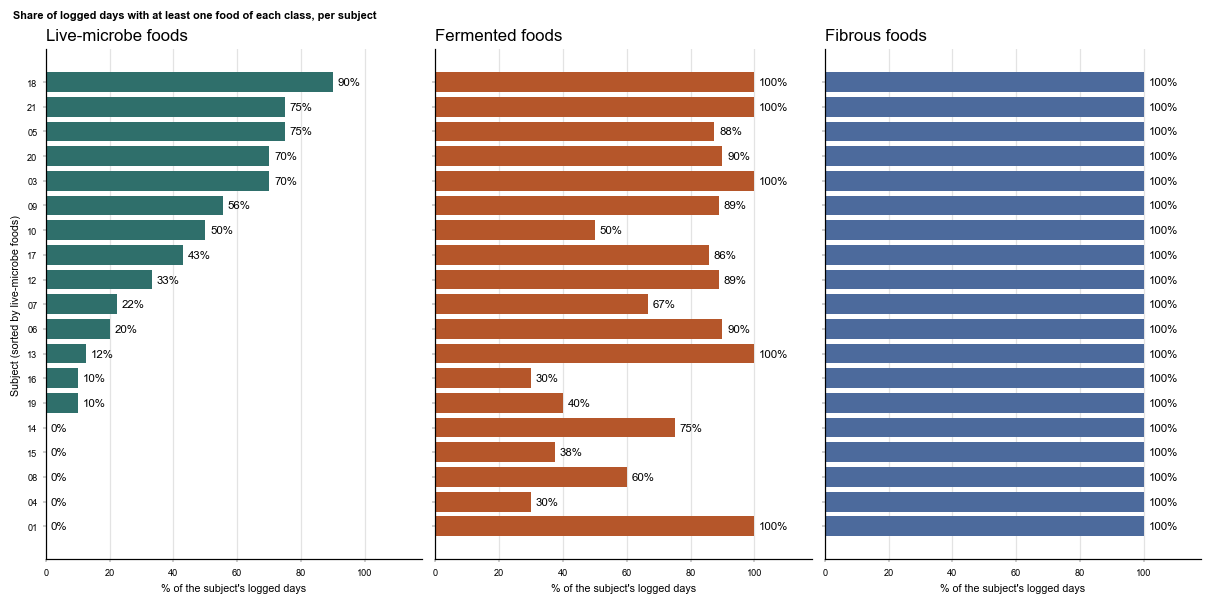

saved: 00_food_classes_per_subject.png, 00_food_classes_per_subject.pdf, 00_food_classes_per_subject.csv


In [7]:
cat = DL.category_days(mentions, sets, subject_days)
print(f"rows (subject-days): {len(cat)}")
for k, label in DL.CATEGORY_LABELS.items():
    print(f"{label}: eaten on {int((cat[f'n_{k}'] > 0).sum())} of {len(cat)} subject-days; "
          f"distinct foods per day: median {cat[f'n_{k}'].median():.0f}, max {cat[f'n_{k}'].max()}")

per_subject = (cat.assign(**{k: cat[f"n_{k}"] > 0 for k in DL.CATEGORY_LABELS})
               .groupby("subject")[list(DL.CATEGORY_LABELS)].mean().mul(100).round(1))
per_subject["logged_days"] = cat.groupby("subject").size()
per_subject = per_subject.sort_values("live")

fig, axes = plt.subplots(1, 3, figsize=(11, 5.5), sharey=True)
for ax, (k, label) in zip(axes, DL.CATEGORY_LABELS.items()):
    ax.barh(per_subject.index, per_subject[k], color=DL.CATEGORY_COLORS[k])
    for subj, v in per_subject[k].items():            # value label on every bar, so 0% is visible too
        ax.text(v + 1.5, subj, f"{v:.0f}%", va="center", fontsize=7.5)
    ax.set_xlim(0, 118)
    ax.set_title(label, fontsize=11)
    ax.set_xlabel("% of the subject's logged days")
    ax.grid(axis="x", color="#E3E3E3"); ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
axes[0].set_ylabel("Subject (sorted by live-microbe foods)")
fig.suptitle("Share of logged days with at least one food of each class, per subject", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
files = DL.save(fig, "00_food_classes_per_subject", per_subject.reset_index(), FIG_FOLDER)
plt.show()
print("saved:", ", ".join(f.name for f in files))

**How to read it:** one row per subject, one panel per food class. The label at the end of each bar is the percentage of
that subject's logged days with at least one food of the class: 100% means every logged day, 0% means never. Subjects with bars between 0 and 100% ate the class on some days and not others: that day-to-day
variation is what a within-person comparison (plan, Q1) relies on.

### 0.6 Day by day: which days had each food class
One row per subject, one column per study day (Day 01-10 from `source_diet_text`). Each panel is one food class.

**What the number in a tile means:** how many **different** foods of that class the subject logged that day.
- A food counts once per day, however many entries mention it. Example: yogurt at breakfast and yogurt as a snack is 1;
  yogurt and kimchi on the same day is 2.
- Live-microbe foods have only 3 members (kimchi, natto, yogurt), so their tiles can only be 1-3. Fermented foods have 14 members
  and fibrous foods 134, so their counts can be much higher.
- Both stated and assumed foods are counted. A **•** after the number means none of that day's foods in the class was
  stated: all were inferred from a dish (e.g. "1•" = one assumed food only).
- **Blank (white) tile:** the day was logged but no food of the class was eaten (count 0).
- **Grey tile:** the subject has no log for that day (not 0, unknown).
- **Colour:** darker = more different foods that day; the colour bar under each panel gives the scale for that class.

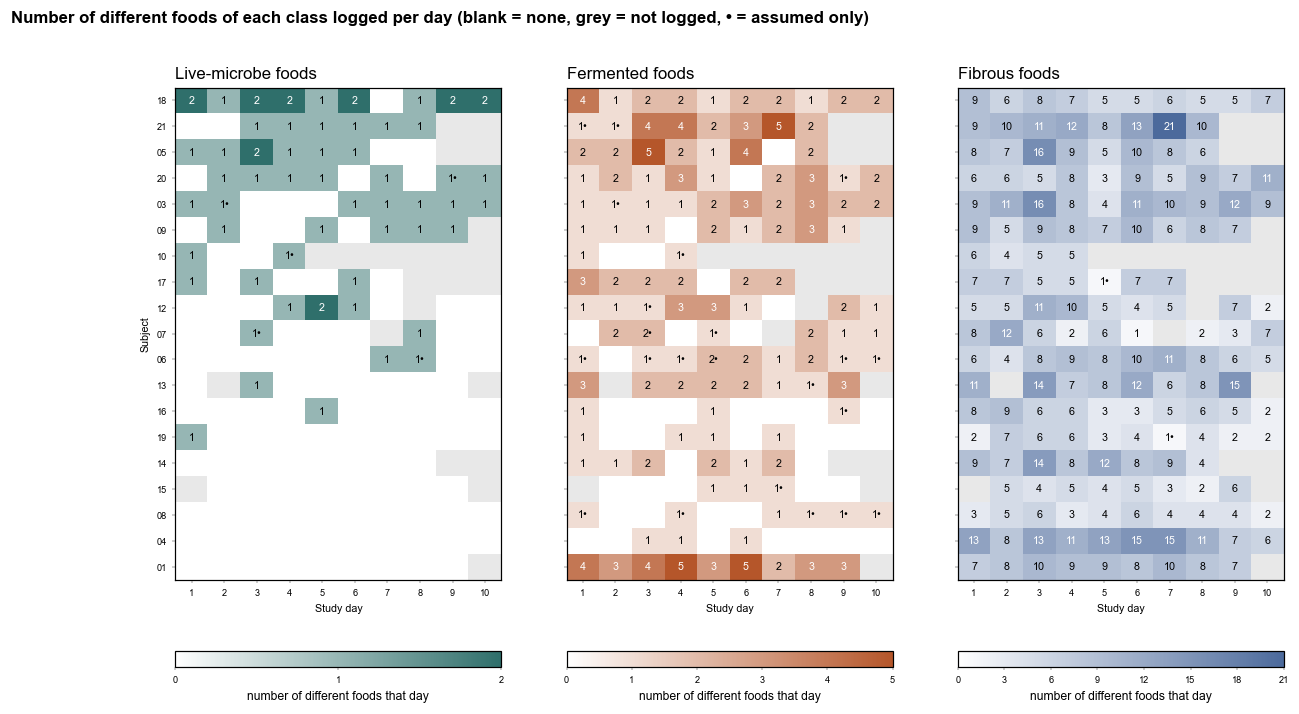

saved: 00_food_classes_by_day.png, 00_food_classes_by_day.pdf, 00_food_classes_by_day.csv


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 7), sharey=True)
order = per_subject.index[::-1]                       # same subject order as the previous figure
days = range(1, int(cat_days_max := subject_days.study_day.max()) + 1)
cat = cat.merge(subject_days[["subject", "date", "study_day"]], on=["subject", "date"])
for ax, (k, label) in zip(axes, DL.CATEGORY_LABELS.items()):
    grid = cat.pivot(index="subject", columns="study_day", values=f"n_{k}").reindex(index=order, columns=days)
    stated = cat.pivot(index="subject", columns="study_day", values=f"stated_{k}").reindex(index=order, columns=days)
    vmax = max(1, int(np.nanmax(grid.values)))
    shown = np.ma.masked_where(~(grid.values > 0), grid.values)   # 0 and not-logged days stay unpainted
    ax.imshow(np.where(np.isnan(grid.values), 1, np.nan), cmap="Greys", vmin=0, vmax=6, aspect="auto")  # grey = not logged
    im = ax.imshow(shown, cmap=plt.matplotlib.colors.LinearSegmentedColormap.from_list("c", ["#FFFFFF", DL.CATEGORY_COLORS[k]]),
                   vmin=0, vmax=vmax, aspect="auto")
    cb = fig.colorbar(im, ax=ax, orientation="horizontal", pad=0.12, fraction=0.05)
    cb.set_label("number of different foods that day", fontsize=8)
    cb.locator = plt.matplotlib.ticker.MaxNLocator(integer=True)   # counts are whole numbers
    cb.update_ticks()
    for i in range(grid.shape[0]):
        for j in range(grid.shape[1]):
            v = grid.values[i, j]
            if v > 0:
                ax.text(j, i, f"{int(v)}" + ("" if stated.values[i, j] else "•"), ha="center", va="center", fontsize=7,
                        color="white" if v > vmax / 2 else "black")
    ax.set_xticks(range(len(days)), days)
    ax.set_yticks(range(len(order)), order)
    ax.set_xlabel("Study day")
    ax.set_title(label, fontsize=11)
axes[0].set_ylabel("Subject")
fig.suptitle("Number of different foods of each class logged per day (blank = none, grey = not logged, • = assumed only)",
             x=0.01, ha="left", fontweight="bold", fontsize=11)
files = DL.save(fig, "00_food_classes_by_day", cat.sort_values(["subject", "study_day"]), FIG_FOLDER)
plt.show()
print("saved:", ", ".join(f.name for f in files))

**How to read it:** read across a row to follow one person through the week. Runs of blank tiles between coloured ones
show days without that food class, i.e. the within-person contrast the plan uses. In the fibrous panel almost every tile is
coloured, so the useful information is the number in the tile (how many different fibrous foods), not whether there is one.

### 0.7 Which foods make up each class
The most frequently logged foods within each class, counted as in 0.3. This shows which foods dominate a class.

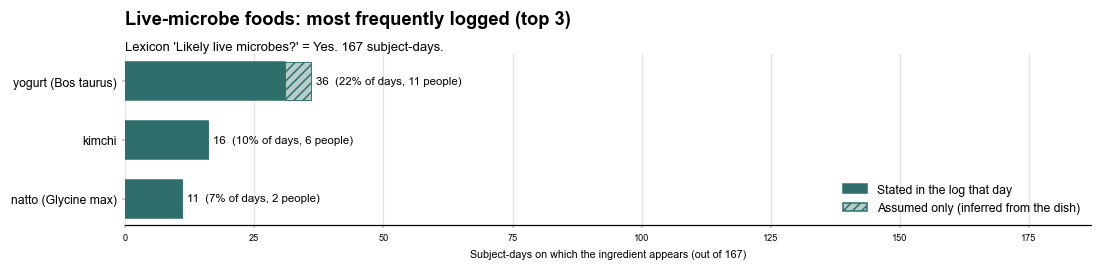

Live-microbe foods: 3 foods in the class, 3 logged at least once; saved: 00_top_live_foods.png, 00_top_live_foods.pdf, 00_top_live_foods.csv


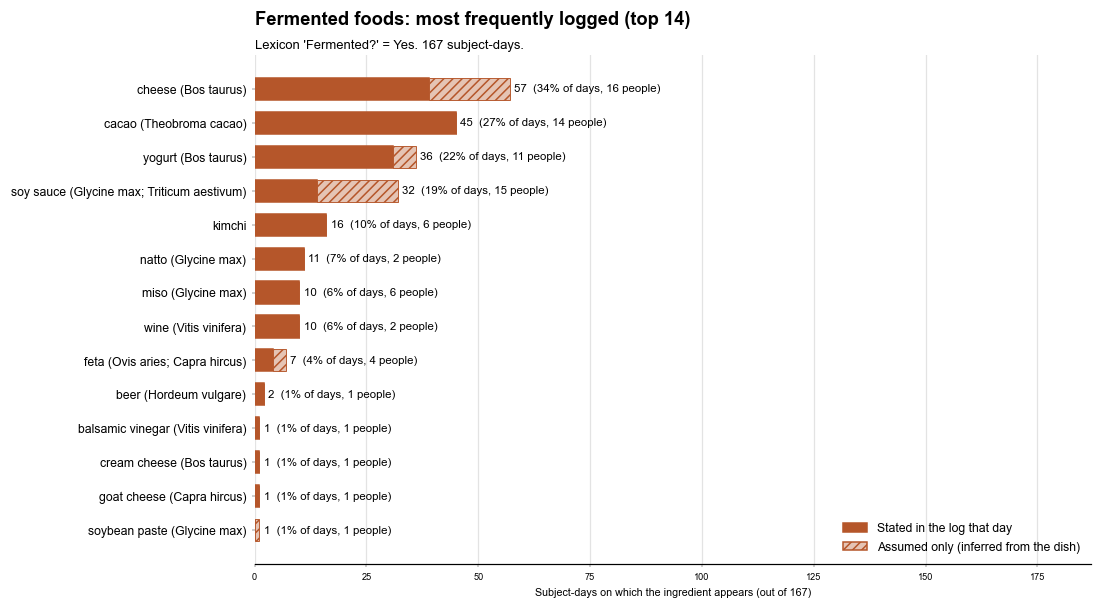

Fermented foods: 14 foods in the class, 14 logged at least once; saved: 00_top_fermented_foods.png, 00_top_fermented_foods.pdf, 00_top_fermented_foods.csv


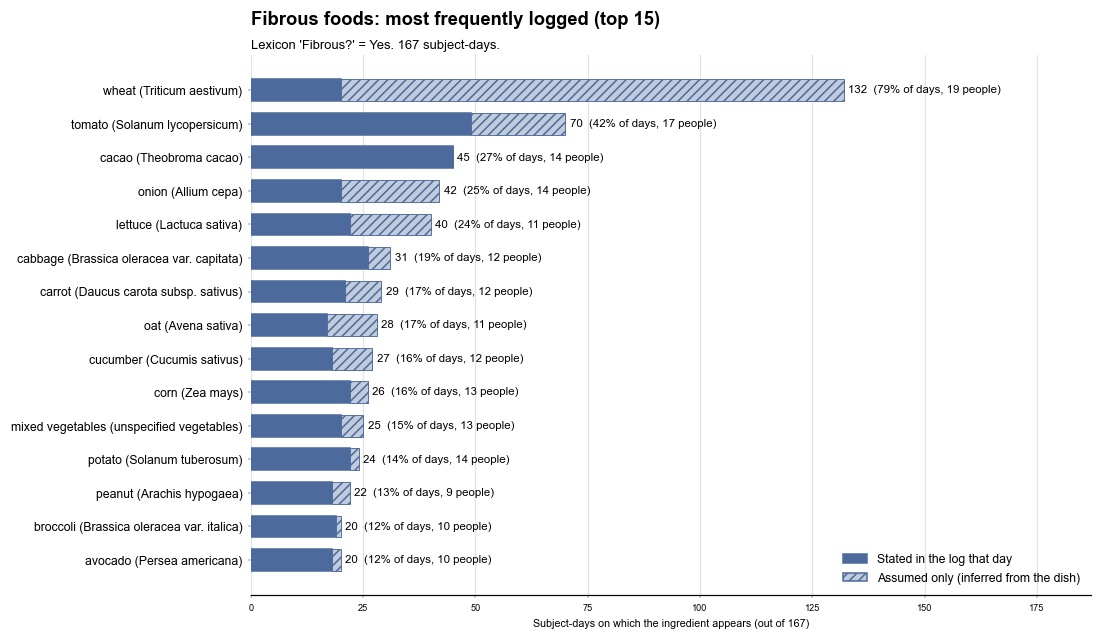

Fibrous foods: 135 foods in the class, 135 logged at least once; saved: 00_top_fibrous_foods.png, 00_top_fibrous_foods.pdf, 00_top_fibrous_foods.csv


In [9]:
for k, label in DL.CATEGORY_LABELS.items():
    sub = freq[freq.ingredient.isin(sets[k])].head(TOP_N_CATEGORY)
    fig = DL.frequency_bars(sub, labels, f"{label}: most frequently logged (top {min(TOP_N_CATEGORY, len(sub))})",
                            f"Lexicon '{DL.LEX_COLS[k].split(' (')[0]}' = Yes. {N_DAYS} subject-days.", N_DAYS,
                            color=DL.CATEGORY_COLORS[k])
    files = DL.save(fig, f"00_top_{k}_foods", sub, FIG_FOLDER)
    plt.show()
    print(f"{label}: {len(sets[k])} foods in the class, {int(freq.ingredient.isin(sets[k]).sum())} logged at least once; "
          "saved:", ", ".join(f.name for f in files))

**How to read it:** as in 0.3, restricted to one class. If one or two foods account for most days (e.g. yogurt among
live-microbe foods), any effect of the class is in practice an effect of those foods.

### 0.8 Fibre as an exposure: number of different fibrous foods per day
Fibrous foods were eaten on every logged day (0.5), so "any fibrous food: yes/no" carries no information.
The fibre exposure is therefore the **number of different fibrous foods** (lexicon `Fibrous? = Yes`) logged per day,
as in the fibrous panel of 0.6. Fibre is a **primary exposure** of the plan (decided 2026-10-18; details in section 1).
Wheat counts as fibrous (lexicon changed from `Variable` to `Yes` on 2026-10-18, user decision), although the log does not say
whether it was whole-grain or refined.

Two versions are counted: **all** fibrous foods (stated and assumed), and **stated only** (foods the subject named).
The gap between them shows how much the count relies on foods inferred from dishes.
**Expected:** 167 subject-days; stated-only counts never larger than all counts.

subject-days: 167; days where stated-only > all: 0
different all fibrous foods per day: median 7, interquartile range 5-9, min 1, max 21
different stated fibrous foods only per day: median 5, interquartile range 3-7, min 0, max 16


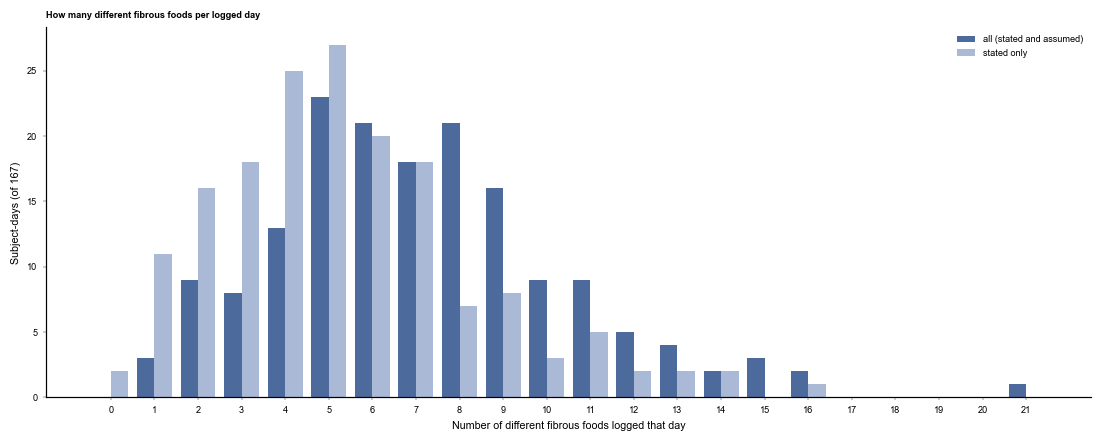

saved: 00_fibre_count_distribution.png, 00_fibre_count_distribution.pdf, 00_fibre_count_distribution.csv


In [10]:
fib = sets["fibrous"]
stated_counts = (mentions[mentions.ingredient.isin(fib) & mentions.stated]
                 .groupby(["subject", "date"]).ingredient.nunique().rename("n_fibrous_stated"))
fibre = (cat[["subject", "date", "study_day", "n_fibrous"]]
         .merge(stated_counts, on=["subject", "date"], how="left").fillna({"n_fibrous_stated": 0}))
fibre["n_fibrous_stated"] = fibre.n_fibrous_stated.astype(int)
print(f"subject-days: {len(fibre)}; days where stated-only > all: {int((fibre.n_fibrous_stated > fibre.n_fibrous).sum())}")
for c, lab in [("n_fibrous", "all fibrous foods"), ("n_fibrous_stated", "stated fibrous foods only")]:
    print(f"different {lab} per day: median {fibre[c].median():.0f}, interquartile range "
          f"{fibre[c].quantile(.25):.0f}-{fibre[c].quantile(.75):.0f}, min {fibre[c].min()}, max {fibre[c].max()}")

# figure 1: how many subject-days had 0, 1, 2, ... different fibrous foods
counts = pd.DataFrame({c: fibre[c].value_counts() for c in ["n_fibrous", "n_fibrous_stated"]}).fillna(0).astype(int)
counts = counts.reindex(range(0, int(counts.index.max()) + 1), fill_value=0)
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(counts))
ax.bar(x - 0.2, counts["n_fibrous"], width=0.4, color=DL.CATEGORY_COLORS["fibrous"], label="all (stated and assumed)")
ax.bar(x + 0.2, counts["n_fibrous_stated"], width=0.4, color="#A9B9D6", label="stated only")
ax.set_xticks(x, counts.index)
ax.set_xlabel("Number of different fibrous foods logged that day")
ax.set_ylabel(f"Subject-days (of {len(fibre)})")
ax.set_title("How many different fibrous foods per logged day", loc="left", fontweight="bold")
ax.legend(frameon=False)
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)
fig.tight_layout()
files = DL.save(fig, "00_fibre_count_distribution", counts.rename_axis("n_different_fibrous_foods").reset_index(), FIG_FOLDER)
plt.show()
print("saved:", ", ".join(f.name for f in files))

**How to read it:** each pair of bars is one possible daily count (0, 1, 2, ... different fibrous foods); the bar height is
the number of subject-days with that count. Dark bars count all fibrous foods, light bars only those the subject named.
A wide spread means the count varies enough to be a useful exposure.

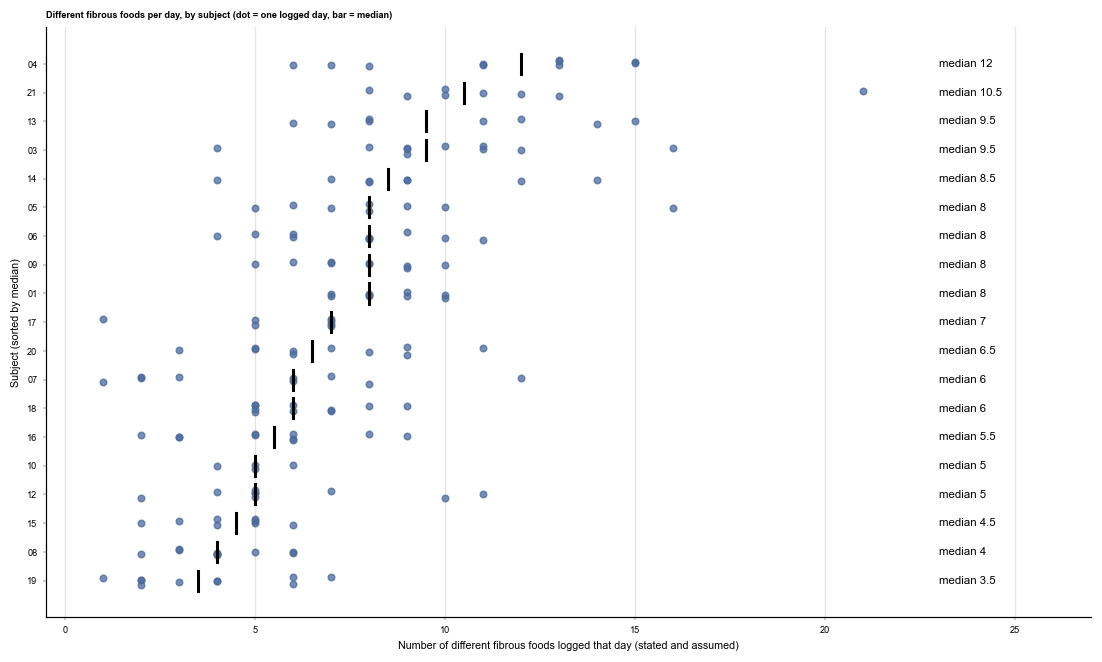

saved: 00_fibre_count_per_subject.png, 00_fibre_count_per_subject.pdf, 00_fibre_count_per_subject.csv


In [11]:
# figure 2: each subject's daily counts (one dot per logged day), subjects sorted by their median
med = fibre.groupby("subject").n_fibrous.median().sort_values()
fig, ax = plt.subplots(figsize=(10, 6))
rng = np.random.default_rng(1)                       # fixed seed: small vertical jitter so overlapping dots stay visible
for i, subj in enumerate(med.index):
    v = fibre.loc[fibre.subject == subj, "n_fibrous"]
    ax.scatter(v, i + rng.uniform(-0.15, 0.15, len(v)), s=18, color=DL.CATEGORY_COLORS["fibrous"], alpha=0.75, zorder=3)
    ax.plot([med[subj]] * 2, [i - 0.35, i + 0.35], color="black", linewidth=2, zorder=4)
    ax.text(fibre.n_fibrous.max() + 2, i, f"median {med[subj]:g}", va="center", fontsize=7.5)
ax.set_yticks(range(len(med)), med.index)
ax.set_xlim(-0.5, fibre.n_fibrous.max() + 6)
ax.set_xlabel("Number of different fibrous foods logged that day (stated and assumed)")
ax.set_ylabel("Subject (sorted by median)")
ax.set_title("Different fibrous foods per day, by subject (dot = one logged day, bar = median)", loc="left", fontweight="bold")
ax.grid(axis="x", color="#E3E3E3"); ax.set_axisbelow(True)
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)
fig.tight_layout()
files = DL.save(fig, "00_fibre_count_per_subject", fibre.sort_values(["subject", "study_day"]), FIG_FOLDER)
plt.show()
print("saved:", ", ".join(f.name for f in files))

**How to read it:** one row per subject; each dot is one logged day, placed at that day's number of different fibrous
foods; the black bar is the subject's median. Differences between rows are between-person differences (habitual fibre
variety, plan Q2); the spread of dots within a row is the day-to-day variation a within-person comparison (Q1) uses.

### 0.9 Does the diet log agree with the questionnaire?
Before the week, each subject answered the `Pre-ingestion-Lifestyle` questionnaire (sample-sheet workbook) about their
usual diet. If the one-week diet log is a fair record, it should broadly agree with these answers. This is a descriptive
check, not a test; subject 11 answered the questionnaire but has no diet log, so is not shown.

Three comparisons are possible with lexicon columns only (CLAUDE.md: no hard-coded food lists):
1. **Fermented food frequency** (`Fermented_food_consumption`) against the percentage of the subject's logged days with at
   least one fermented food, for four lexicon definitions: `Likely live microbes?` and `Fermented?`, each counting
   `Yes` only (the definitions used elsewhere) and `Yes` + `Variable` (foods that may or may not qualify, e.g. cheese
   for live microbes, coffee for fermented; listed in 0.4).
2. **Dairy frequency** (`Dairy_consumption`) against the percentage of logged days with at least one dairy food (lexicon
   `Dairy? = Yes`, added 2026-10-18; also `Yes` + `Variable`, i.e. with protein powder).
3. **Self-reported vegan or vegetarian diet** against animal foods in the log. An ingredient counts as animal-derived when its
   lexicon `Class` is an animal class (Mammalia, Aves, Actinopteri, Malacostraca, Cephalopoda, Bivalvia). The lexicon cannot
   separate meat from dairy or eggs (cow milk and beef are both *Bos taurus*), so for vegetarians the foods are listed by name.

**Expected:** 19 subjects with both a questionnaire answer and a diet log.

Yes-only columns equal to section 0.5: True
subjects with a diet log: 19; with a questionnaire answer: 19
answers not in the expected list: []


Live-microbe foods, Yes (3 foods): Spearman rank correlation with the answer 0.39 (descriptive); subjects inside the answer's expected range 6 of 19
Live-microbe foods, Yes + Variable (16 foods): Spearman rank correlation with the answer 0.28 (descriptive); subjects inside the answer's expected range 4 of 19
Fermented foods, Yes (14 foods): Spearman rank correlation with the answer 0.23 (descriptive); subjects inside the answer's expected range 2 of 19
Fermented foods, Yes + Variable (26 foods): Spearman rank correlation with the answer 0.16 (descriptive); subjects inside the answer's expected range 5 of 19


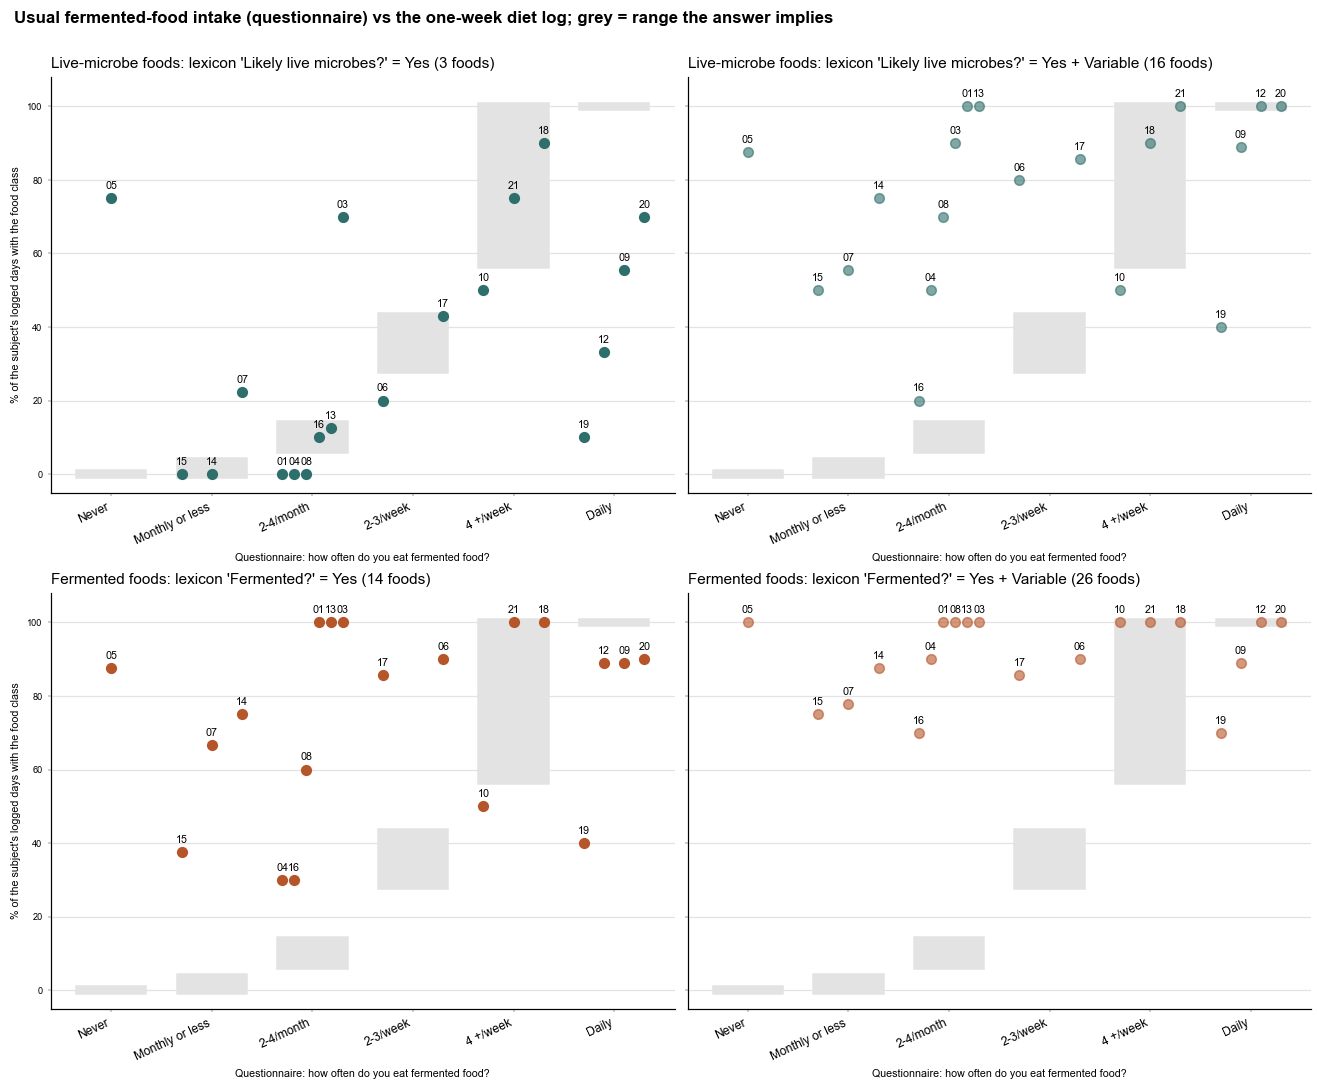

saved: 00_questionnaire_fermented_vs_log.png, 00_questionnaire_fermented_vs_log.pdf, 00_questionnaire_fermented_vs_log.csv


In [12]:
lif = C.read_excel_like_readxl(C.SAMPLE_SHEET, sheet_name="Pre-ingestion-Lifestyle")
lif["subject"] = lif["Subject_ID"].astype(str)
FREQ_ORDER = ["Never", "Monthly or less", "2-4 times per month", "2-3 times per week",
              "4 or more times per week", "Daily (at least once a day)"]
# share of days on which a food would appear if the answer were exactly right (min-max of the answer's range)
EXPECTED_PCT = {"Never": (0, 0), "Monthly or less": (0, 100 / 30), "2-4 times per month": (200 / 30, 400 / 30),
                "2-3 times per week": (200 / 7, 300 / 7), "4 or more times per week": (400 / 7, 100),
                "Daily (at least once a day)": (100, 100)}
# four definitions: Yes only, and Yes + Variable, for live-microbe and fermented foods
DEFS = {"live": ("Live-microbe foods", "Yes", sets["live"]),
        "live_var": ("Live-microbe foods", "Yes + Variable", sets["live"] | variable["live"]),
        "fermented": ("Fermented foods", "Yes", sets["fermented"]),
        "fermented_var": ("Fermented foods", "Yes + Variable", sets["fermented"] | variable["fermented"])}
days_with = {k: mentions[mentions.ingredient.isin(foods)].groupby("subject").date.nunique() for k, (_, _, foods) in DEFS.items()}
q = pd.DataFrame({k: (100 * days_with[k].reindex(per_subject.index).fillna(0) / per_subject.logged_days).round(1) for k in DEFS})
q = q.join(lif.set_index("subject")["Fermented_food_consumption"], how="left")
# the Yes-only columns must equal 0.5's percentages (same definition, computed another way)
print("Yes-only columns equal to section 0.5:", bool((q.live == per_subject.live).all() and (q.fermented == per_subject.fermented).all()))
print(f"subjects with a diet log: {len(per_subject)}; with a questionnaire answer: {int(q.Fermented_food_consumption.notna().sum())}")
print("answers not in the expected list:", sorted(set(q.Fermented_food_consumption.dropna()) - set(FREQ_ORDER)))
q["answer_rank"] = q.Fermented_food_consumption.map({a: i for i, a in enumerate(FREQ_ORDER)})
for k, (name, level, foods) in DEFS.items():
    q[f"within_expected_{k}"] = [EXPECTED_PCT[a][0] - 1e-9 <= v <= EXPECTED_PCT[a][1] + 1e-9
                                 for a, v in zip(q.Fermented_food_consumption, q[k])]
    rho = q[k].corr(q.answer_rank, method="spearman")
    print(f"{name}, {level} ({len(foods)} foods): Spearman rank correlation with the answer {rho:.2f} (descriptive); "
          f"subjects inside the answer's expected range {int(q[f'within_expected_{k}'].sum())} of {len(q)}")

fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharey=True)
for ax, k in zip(axes.ravel(), DEFS):
    for i, a in enumerate(FREQ_ORDER):
        lo, hi = EXPECTED_PCT[a]
        ax.add_patch(plt.Rectangle((i - 0.35, lo - 1), 0.7, hi - lo + 2, color="#E3E3E3", zorder=1))
    # spread subjects with the same answer evenly across the column, so dots and labels do not overlap
    pos = q.groupby("answer_rank")[k].rank(method="first") - 1
    size = q.groupby("answer_rank")[k].transform("size")
    xs = q.answer_rank + np.where(size > 1, -0.3 + 0.6 * pos / (size - 1).clip(lower=1), 0)
    for subj, x, y in zip(q.index, xs, q[k]):
        ax.text(x, y + 2.5, subj, fontsize=7, ha="center", zorder=4)
    ax.set_xticks(range(len(FREQ_ORDER)), [a.replace(" (at least once a day)", "").replace(" times per ", "/").replace("or more", "+")
                                           for a in FREQ_ORDER], rotation=25, ha="right", fontsize=8)
    ax.set_xlim(-0.6, len(FREQ_ORDER) - 0.4); ax.set_ylim(-5, 108)
    name, level, foods = DEFS[k]
    base = k.replace("_var", "")
    ax.scatter(xs, q[k], s=40, color=DL.CATEGORY_COLORS[base], zorder=3, alpha=1.0 if level == "Yes" else 0.6)
    ax.set_title(f"{name}: lexicon '{DL.LEX_COLS[base].split(' (')[0]}' = {level} ({len(foods)} foods)", fontsize=10)
    ax.set_xlabel("Questionnaire: how often do you eat fermented food?")
    ax.grid(axis="y", color="#E3E3E3"); ax.set_axisbelow(True)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
for ax in axes[:, 0]:
    ax.set_ylabel("% of the subject's logged days with the food class")
fig.suptitle("Usual fermented-food intake (questionnaire) vs the one-week diet log; grey = range the answer implies",
             x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.97))   # leave room for the main title
files = DL.save(fig, "00_questionnaire_fermented_vs_log", q.reset_index().rename(columns={"index": "subject"}), FIG_FOLDER)
plt.show()
print("saved:", ", ".join(f.name for f in files))

**How to read it:** one dot per subject (labelled), placed at their questionnaire answer (x) and the percentage of their
logged days with the food class (y). The grey box shows the range that answer implies (e.g. "2-3 times per week" = 29-43%
of days; "Daily" = 100%). Dots inside or near their grey box agree with the questionnaire; dots far above or below do not.
The four panels differ only in the definition (rows: live-microbe vs fermented; columns: `Yes` only vs `Yes` + `Variable`).
Adding `Variable` foods can only raise a subject's percentage, so dots move up from left to right. Subjects probably did not
think of soy sauce, cacao, cheese or coffee as "fermented food" when answering, so the narrower definitions may match their
idea of the question better.

dairy foods (Yes): 11: butter, cheese, cow milk, cream, cream cheese, feta, goat cheese, ice cream, paneer, whey, yogurt; Variable: protein powder
dairy answers not in the expected list: []
Dairy foods, Yes (11 foods): Spearman rank correlation with the answer 0.57 (descriptive); subjects inside the answer's expected range 10 of 19
Dairy foods, Yes + Variable (12 foods): Spearman rank correlation with the answer 0.56 (descriptive); subjects inside the answer's expected range 11 of 19


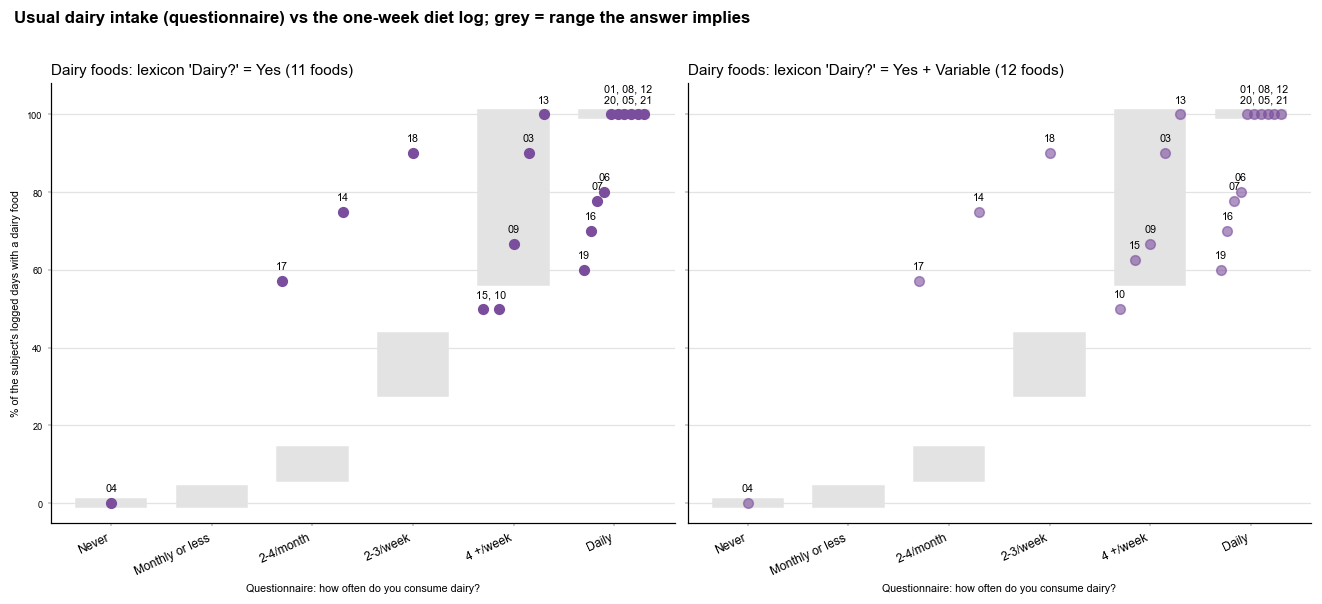

saved: 00_questionnaire_dairy_vs_log.png, 00_questionnaire_dairy_vs_log.pdf, 00_questionnaire_dairy_vs_log.csv


In [13]:
# dairy: lexicon Dairy? column, same layout as the fermented-food figure (answers use the same frequency scale)
dairy_yes = set(lexicon.loc[lexicon[DL.LEX_COLS["dairy"]] == "Yes", "Ingredient"])
dairy_var = set(lexicon.loc[lexicon[DL.LEX_COLS["dairy"]] == "Variable", "Ingredient"])
DDEFS = {"dairy": ("Dairy foods", "Yes", dairy_yes), "dairy_var": ("Dairy foods", "Yes + Variable", dairy_yes | dairy_var)}
qd = pd.DataFrame({k: (100 * mentions[mentions.ingredient.isin(f)].groupby("subject").date.nunique()
                         .reindex(per_subject.index).fillna(0) / per_subject.logged_days).round(1) for k, (_, _, f) in DDEFS.items()})
qd = qd.join(lif.set_index("subject")["Dairy_consumption"], how="left")
print(f"dairy foods (Yes): {len(dairy_yes)}: {', '.join(sorted(dairy_yes))}; Variable: {', '.join(sorted(dairy_var))}")
print("dairy answers not in the expected list:", sorted(set(qd.Dairy_consumption.dropna()) - set(FREQ_ORDER)))
qd["answer_rank"] = qd.Dairy_consumption.map({a: i for i, a in enumerate(FREQ_ORDER)})
for k, (name, level, foods) in DDEFS.items():
    qd[f"within_expected_{k}"] = [EXPECTED_PCT[a][0] - 1e-9 <= v <= EXPECTED_PCT[a][1] + 1e-9
                                  for a, v in zip(qd.Dairy_consumption, qd[k])]
    print(f"{name}, {level} ({len(foods)} foods): Spearman rank correlation with the answer "
          f"{qd[k].corr(qd.answer_rank, method='spearman'):.2f} (descriptive); subjects inside the answer's expected range "
          f"{int(qd[f'within_expected_{k}'].sum())} of {len(qd)}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True)
for ax, k in zip(axes, DDEFS):
    name, level, foods = DDEFS[k]
    for i, a in enumerate(FREQ_ORDER):
        lo, hi = EXPECTED_PCT[a]
        ax.add_patch(plt.Rectangle((i - 0.35, lo - 1), 0.7, hi - lo + 2, color="#E3E3E3", zorder=1))
    pos = qd.groupby("answer_rank")[k].rank(method="first") - 1
    size = qd.groupby("answer_rank")[k].transform("size")
    xs = qd.answer_rank + np.where(size > 1, -0.3 + 0.6 * pos / (size - 1).clip(lower=1), 0)
    ax.scatter(xs, qd[k], s=40, color="#7A4E9C", zorder=3, alpha=1.0 if level == "Yes" else 0.6)
    # subjects with the same answer and the same percentage share one label (avoids overlapping text)
    lab = pd.DataFrame({"subj": qd.index, "x": xs.values, "y": qd[k].values, "a": qd.answer_rank.values})
    for (_, y), g in lab.groupby(["a", "y"]):
        text = ", ".join(g.subj) if len(g) <= 3 else chr(10).join(", ".join(g.subj[i:i + 3]) for i in range(0, len(g), 3))
        ax.text(g.x.mean(), y + 2.5, text, fontsize=7, ha="center", va="bottom", zorder=4)
    ax.set_xticks(range(len(FREQ_ORDER)), [a.replace(" (at least once a day)", "").replace(" times per ", "/").replace("or more", "+")
                                           for a in FREQ_ORDER], rotation=25, ha="right", fontsize=8)
    ax.set_xlim(-0.6, len(FREQ_ORDER) - 0.4); ax.set_ylim(-5, 108)
    ax.set_title(f"{name}: lexicon 'Dairy?' = {level} ({len(foods)} foods)", fontsize=10)
    ax.set_xlabel("Questionnaire: how often do you consume dairy?")
    ax.grid(axis="y", color="#E3E3E3"); ax.set_axisbelow(True)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
axes[0].set_ylabel("% of the subject's logged days with a dairy food")
fig.suptitle("Usual dairy intake (questionnaire) vs the one-week diet log; grey = range the answer implies",
             x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.95))
files = DL.save(fig, "00_questionnaire_dairy_vs_log", qd.reset_index().rename(columns={"index": "subject"}), FIG_FOLDER)
plt.show()
print("saved:", ", ".join(f.name for f in files))

**How to read it:** as the fermented-food figure: one dot per subject at their questionnaire answer (x) and the percentage of
their logged days with at least one dairy food (y); grey boxes show the range the answer implies. The right panel also counts
protein powder (`Dairy? = Variable`), which may or may not contain whey.

animal-derived lexicon ingredients (by Class): 39
subjects reporting a vegan, vegetarian or pescatarian diet (with a diet log): {'03': 'Vegetarian', '04': 'Vegan', '20': 'Vegetarian'}
reported but no diet log: {'11': ['Vegetarian']}
subject reported_diet ingredient    class  subject_days  days_stated  logged_days
     03    Vegetarian     yogurt Mammalia             7            6           10
     03    Vegetarian   cow milk Mammalia             5            1           10
     03    Vegetarian        egg     Aves             5            1           10
     03    Vegetarian     butter Mammalia             3            0           10
     03    Vegetarian     cheese Mammalia             2            2           10
     03    Vegetarian       feta Mammalia             1            0           10
     03    Vegetarian    gelatin Mammalia             1            0           10
     03    Vegetarian  ice cream Mammalia             1            1           10
     03    Vegetarian       w

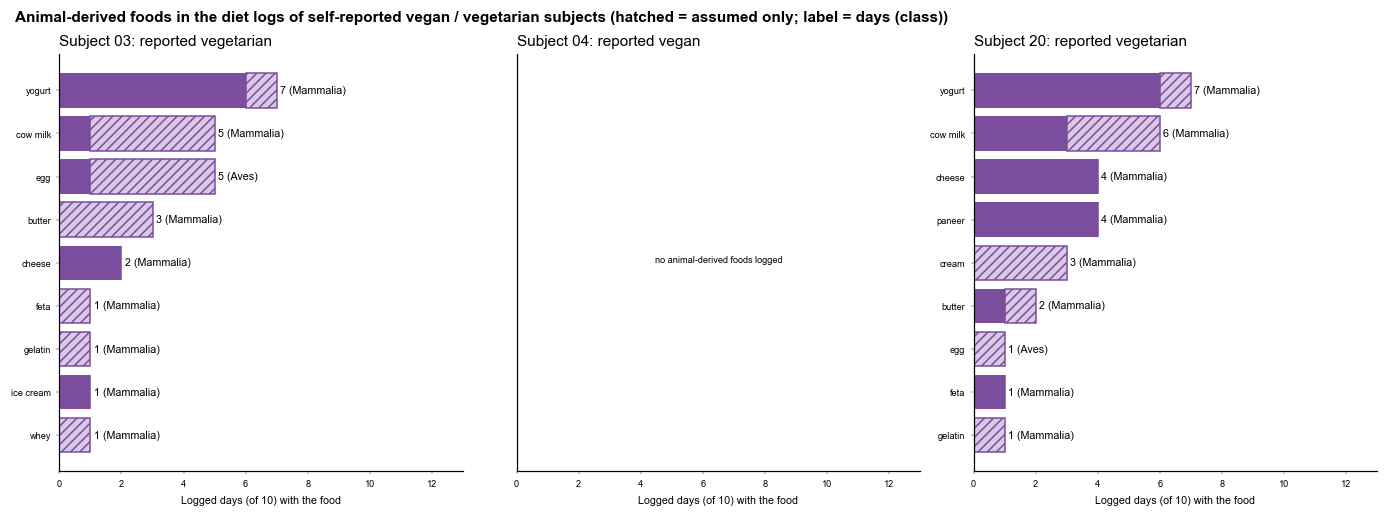

saved: 00_questionnaire_diet_type_vs_log.png, 00_questionnaire_diet_type_vs_log.pdf, 00_questionnaire_diet_type_vs_log.csv


In [14]:
ANIMAL_CLASSES = {"Mammalia", "Aves", "Actinopteri", "Malacostraca", "Cephalopoda", "Bivalvia"}
animal = {r.Ingredient for r in lexicon.itertuples(index=False)
          if isinstance(r.Class, str) and ANIMAL_CLASSES & {c.strip() for c in r.Class.split(";")}}
self_report = {subj: [d for d in ("Vegan", "Vegetarian", "Pescatarian") if lif.set_index("subject").at[subj, d] == "Yes"]
               for subj in lif.subject}
plant_based = {subj: d[0] for subj, d in self_report.items() if d and subj in set(per_subject.index)}
print(f"animal-derived lexicon ingredients (by Class): {len(animal)}")
print("subjects reporting a vegan, vegetarian or pescatarian diet (with a diet log):", plant_based or "none")
print("reported but no diet log:", {s: d for s, d in self_report.items() if d and s not in set(per_subject.index)})

rows = []
for subj, dtype in plant_based.items():
    m = mentions[(mentions.subject == subj) & mentions.ingredient.isin(animal)]
    days = m.groupby("ingredient").agg(subject_days=("date", "nunique"), days_stated=("date", lambda d: m.loc[d.index][m.loc[d.index].stated].date.nunique()))
    for ing, r in days.iterrows():
        rows.append({"subject": subj, "reported_diet": dtype, "ingredient": ing, "class": "; ".join(dict.fromkeys(c.strip() for c in lexicon.set_index("Ingredient").at[ing, "Class"].split(";"))),
                     "subject_days": int(r.subject_days), "days_stated": int(r.days_stated),
                     "logged_days": int(per_subject.at[subj, "logged_days"])})
animal_log = pd.DataFrame(rows).sort_values(["subject", "subject_days"], ascending=[True, False])
print(animal_log.to_string(index=False) if len(animal_log) else "no animal-derived ingredients logged by these subjects")

fig, axes = plt.subplots(1, len(plant_based), figsize=(4.2 * len(plant_based), 0.32 * max(3, animal_log.groupby("subject").size().max()) + 1.8), squeeze=False)
for ax, (subj, dtype) in zip(axes[0], plant_based.items()):
    d = animal_log[animal_log.subject == subj].iloc[::-1]
    nd = int(per_subject.at[subj, "logged_days"])
    if len(d):
        ax.barh(d.ingredient, d.days_stated, color="#7A4E9C")
        ax.barh(d.ingredient, d.subject_days - d.days_stated, left=d.days_stated, color="#D9C8E6", hatch="////", edgecolor="#7A4E9C")
        for i, r in enumerate(d.itertuples(index=False)):
            ax.text(r.subject_days + 0.1, i, f"{r.subject_days} ({r._3})", va="center", fontsize=7)
    else:
        ax.text(0.5, 0.5, "no animal-derived foods logged", transform=ax.transAxes, ha="center")
        ax.set_yticks([])
    ax.set_xlim(0, nd + 3)
    ax.set_xlabel(f"Logged days (of {nd}) with the food")
    ax.set_title(f"Subject {subj}: reported {dtype.lower()}", fontsize=10)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
fig.suptitle("Animal-derived foods in the diet logs of self-reported vegan / vegetarian subjects (hatched = assumed only; label = days (class))",
             x=0.01, ha="left", fontweight="bold", fontsize=10)
fig.tight_layout()
files = DL.save(fig, "00_questionnaire_diet_type_vs_log", animal_log, FIG_FOLDER)
plt.show()
print("saved:", ", ".join(f.name for f in files))

**How to read it:** one panel per self-reported vegan or vegetarian subject, listing every logged ingredient whose lexicon
class is an animal class, with the number of that subject's logged days on which it appears (solid = named in the log,
hatched = only inferred from a dish). For a vegan, any bar disagrees with the questionnaire. For a vegetarian, dairy and egg
are expected; meat or fish names (e.g. chicken, beef, salmon) would disagree. Assumed-only bars may reflect the coding
(e.g. butter assumed in a pastry) rather than what was eaten.